# Лабораторная работа №4: Деревья решений

## Цель:
Изучить принципы построения деревьев решений для задач классификации и регрессии; освоить методы построения, визуализации и оценки моделей с использованием Python и библиотеки scikit-learn; экспериментально исследовать влияние сложности дерева на качество предсказаний, выявить признаки переобучения и сравнить результаты работы дерева решений с альтернативным алгоритмом машинного обучения.
## Описание:
Деревья решений - это алгоритмы машинного обучения, которые строят последовательность правил для прогнозирования значения целевой переменной. В каждом внутреннем узле дерева выполняется проверка условия над одним из признаков, а результат проверки определяет переход к следующему узлу. В листьях дерева формируется прогноз.

Деревья решений применяются для решения двух основных типов задач:
- Классификация - прогнозирование категориальной целевой переменной.
- Регрессия - прогнозирование числовой целевой переменной.

При построении дерева алгоритм последовательно выбирает разбиения данных, улучшить качество прогнозирования. Для классификации могут использоваться критерий Джини и энтропия, для регрессии - критерии, основанные на ошибке предсказаний. Одно из преимуществ деревьев решений - возможность интерпретировать полученные правила. Однако слишком сложное дерево может хорошо описывать обучающие данные, но плохо работать на новых объектах. Такое явление называется переобучением. В ходе лабораторной работы необходимо не только построить модель, но и экспериментально установить, как параметры дерева влияют на качество прогнозирования и способность модели обобщать закономерности.

---
### 1. Выбор датасета и постановка задачи

Источник: https://www.kaggle.com/datasets/rishabhrajsharma/intermediate-core-ml-assignment-dataset

Intermediate CoreML Assignment Dataset — это синтетический, но реалистичный набор аналитики клиентов, предназначенный для обучения и практики в области машинного обучения.

Он содержит как числовые, так и категориальные признаки, включает отсутствующие значения и предоставляет две цели:
- target_reg → регрессионная цель для линейной регрессии, градиентного спуска, регуляризации
- churn → несбалансированная бинарная цель для классификационных моделей

Признаки:

| Поле             | Описание                                            | Перевод |
|------------------|-----------------------------------------------------|---------|
| customer_id      | Unique customer identifier (do not use in training) | Уникальный идентификатор клиента (не использовать во время обучения) |
| age              | Customer age (years)                                | Возраст клиента (лет) |
| tenure_months    | Customer tenure in months                           | Срок сотрудничества с клиентом в месяцах |
| income           | Annual income (contains missing values)             | Годовой доход (содержит пропущенные значения) |
| credit_score     | Credit score 300–850 (contains missing values)      | Кредитный рейтинг 300–850 (содержит пропущенные значения) |
| monthly_charges  | Monthly service charge (contains missing values)    | Ежемесячная плата за обслуживание (содержит пропущенные значения) |
| support_tickets  | Number of support tickets raised                    | Количество обращений в службу поддержки |
| avg_session_time | Avg usage session time (minutes)                    | Среднее время сеанса использования (минуты) |
| late_payments    | Count of late payments                              | Количество просроченных платежей |
| gender           | Gender                                              | Пол |

* Тип задачи: Бинарная классификация
* Целевая переменная: churn (0 — клиент остался, 1 — клиент ушел/отток)
* Прикладная цель: Построить интерпретируемую предиктивную модель для телеком компании, которая выявляет клиентов с высоким риском оттока. Это позволит отделу маркетинга и удержания вовремя предложить персональные скидки или решить проблемы с сервисом
* Исключаемые признаки:
  * customer_id — технический идентификатор, не несет физического смысла и ведет к переобучению
  * target_reg — непрерывная переменная для регрессии (ее использование приведет к утечке данных, так как она моделирует связанную метрику ценности клиента)

---

### 2. Первичный анализ данных и подготовка выборок

In [1]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, f1_score, balanced_accuracy_score, ConfusionMatrixDisplay, classification_report)
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# загрузка датасета
df = pd.read_csv('C:\\Desktop\\Education\\5 семестр\\ML\\LW №4\\data\\intermediate_coreml_assignment_dataset.csv')

# проверим форму данных и типы
print("Размерность датасета:", df.shape)
df.info()
display(df.head())

Размерность датасета: (50000, 18)
<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   customer_id        50000 non-null  int64  
 1   age                50000 non-null  int64  
 2   tenure_months      50000 non-null  int64  
 3   income             49305 non-null  float64
 4   credit_score       49183 non-null  float64
 5   monthly_charges    49171 non-null  float64
 6   support_tickets    50000 non-null  int64  
 7   avg_session_time   50000 non-null  float64
 8   late_payments      50000 non-null  int64  
 9   gender             49200 non-null  str    
 10  city_tier          50000 non-null  str    
 11  plan_type          50000 non-null  str    
 12  payment_method     49187 non-null  str    
 13  device_type        50000 non-null  str    
 14  has_international  50000 non-null  str    
 15  is_student         50000 non-null  str    
 16 

,customer_id,age,tenure_months,income,credit_score,monthly_charges,support_tickets,avg_session_time,late_payments,gender,city_tier,plan_type,payment_method,device_type,has_international,is_student,target_reg,churn
0,200001,51,6,23039.19,718.0,1065.30,0,28.36,0,Female,Tier1,Basic,UPI,Android,No,No,44030.77,0
1,200002,46,116,54173.02,491.0,1035.67,1,15.75,0,Male,Tier2,Basic,Card,Android,No,No,138673.42,0
2,200003,20,112,37130.61,623.0,897.50,1,15.15,0,Female,Tier1,Standard,Card,Android,No,No,159250.49,0
3,200004,18,53,39873.95,850.0,1095.42,3,26.83,0,Male,Tier1,Standard,UPI,Android,No,No,109410.17,1
4,200005,22,60,39591.09,779.0,1422.29,0,18.83,0,Male,Tier2,Premium,Card,Android,No,No,91008.23,0


Дубликатов в данных: 0

Пропуски по столбцам:
income             695
credit_score       817
monthly_charges    829
gender             800
payment_method     813
dtype: int64


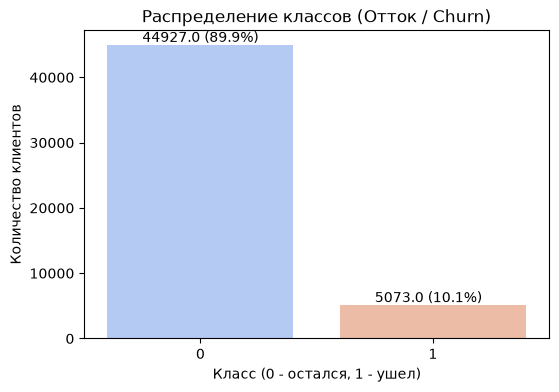

Описательные статистики числовых признаков:


,count,mean,std,min,25%,50%,75%,max
age,50000.0,41.216260,13.818791,18.0,29.000,41.00,53.00,65.00
tenure_months,50000.0,59.212880,34.976033,0.0,30.000,59.00,89.00,120.00
income,49305.0,44802.597299,14951.337403,8000.0,34744.270,44688.01,54330.26,92535.91
credit_score,49183.0,570.410691,159.033340,301.0,436.000,568.00,704.00,850.00
monthly_charges,49171.0,1196.449165,452.227406,200.0,887.335,1193.13,1509.64,2595.86
support_tickets,50000.0,1.183460,1.094361,0.0,0.000,1.00,2.00,5.00
avg_session_time,50000.0,18.018672,6.052666,2.0,13.880,18.09,22.20,36.53
late_payments,50000.0,0.257940,0.512028,0.0,0.000,0.00,0.00,3.00


Размер train: (40000, 15), размер test: (10000, 15)


In [2]:
# 1 проверка пропусков и дубликатов
print("Дубликатов в данных:", df.duplicated().sum())
print("\nПропуски по столбцам:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# 2 анализ распределения целевой переменной (Дисбаланс классов)
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x='churn', palette='coolwarm')
plt.title("Распределение классов (Отток / Churn)")
plt.xlabel("Класс (0 - остался, 1 - ушел)")
plt.ylabel("Количество клиентов")
for p in ax.patches:
    ax.annotate(f'{p.get_height()} ({p.get_height()/len(df)*100:.1f}%)',
                (p.get_x() + 0.15, p.get_height() + 500))
plt.show()

# 3 разделение признаков и целевой переменной
X = df.drop(columns=['customer_id', 'target_reg', 'churn'])
y = df['churn']

# Определяем списки признаков
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X.select_dtypes(include=['object', 'str']).columns.tolist()

print("Описательные статистики числовых признаков:")
display(df[num_cols].describe().T)

# 4 разбиение на обучающую и тестовую выборки (80 на 20, стратифицированное - с сохранением распределения классов)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Размер train: {X_train.shape}, размер test: {X_test.shape}")

* Наблюдаем сильный дисбаланс классов (примерно 10% - отток, когда остальные 90% - лояльные клиенты), что усложнит нам задачу классификации
* Также наблюдаем, что числовые данные находятся в адекватных пределах, однако присутствуют пропуски
* Видим разницу в масштабе данных, однако для дерева решений это не имеет значения (в отличии от логистической регрессии)
* Замечаем из признака late_payments, что более 75% клиентов не имеют просрочек (min = 0, 25% = 0, 50% (медиана) = 0, 75% = 0, max = 3), следовательно можем предположить, что late_payments - это достаточно редкое событие и скорее всего тревожный сигнал для нашей задачи классификации

#### Предобработка без утечки данных (ColumnTransformer):
Деревьям решений нормализация не нужна, но категориальные признаки необходимо закодировать (One-Hot Encoding), а пропуски - заполнить (медианой для чисел и модой для категорий)

In [3]:
# числовые признаки: заполняем пропуски медианой (устойчива к выбросам)
num_transformer = SimpleImputer(strategy='median')

# категориальные признаки: заполняем пропуски модой и кодируем One-Hot
cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# применяем соответствующие трансформеры к признакам
preprocessor = ColumnTransformer(transformers=[
    ('num', num_transformer, num_cols),
    ('cat', cat_transformer, cat_cols)
])

X_train_prep = preprocessor.fit_transform(X_train) # обучаем препроцессор ТОЛЬКО на обучающей выборке
X_test_prep = preprocessor.transform(X_test) # применяем к тесту

# получаем понятные названия признаков после One-Hot Encoding
feature_names = num_cols + list(preprocessor.named_transformers_['cat'].named_steps['onehot'].get_feature_names_out(cat_cols))

---

### 3. Построение и интерпретация базового дерева решений

Построим базовое дерево без ограничения глубины

Глубина базового дерева: 42
Количество листьев: 4931
Общее количество узлов: 9861


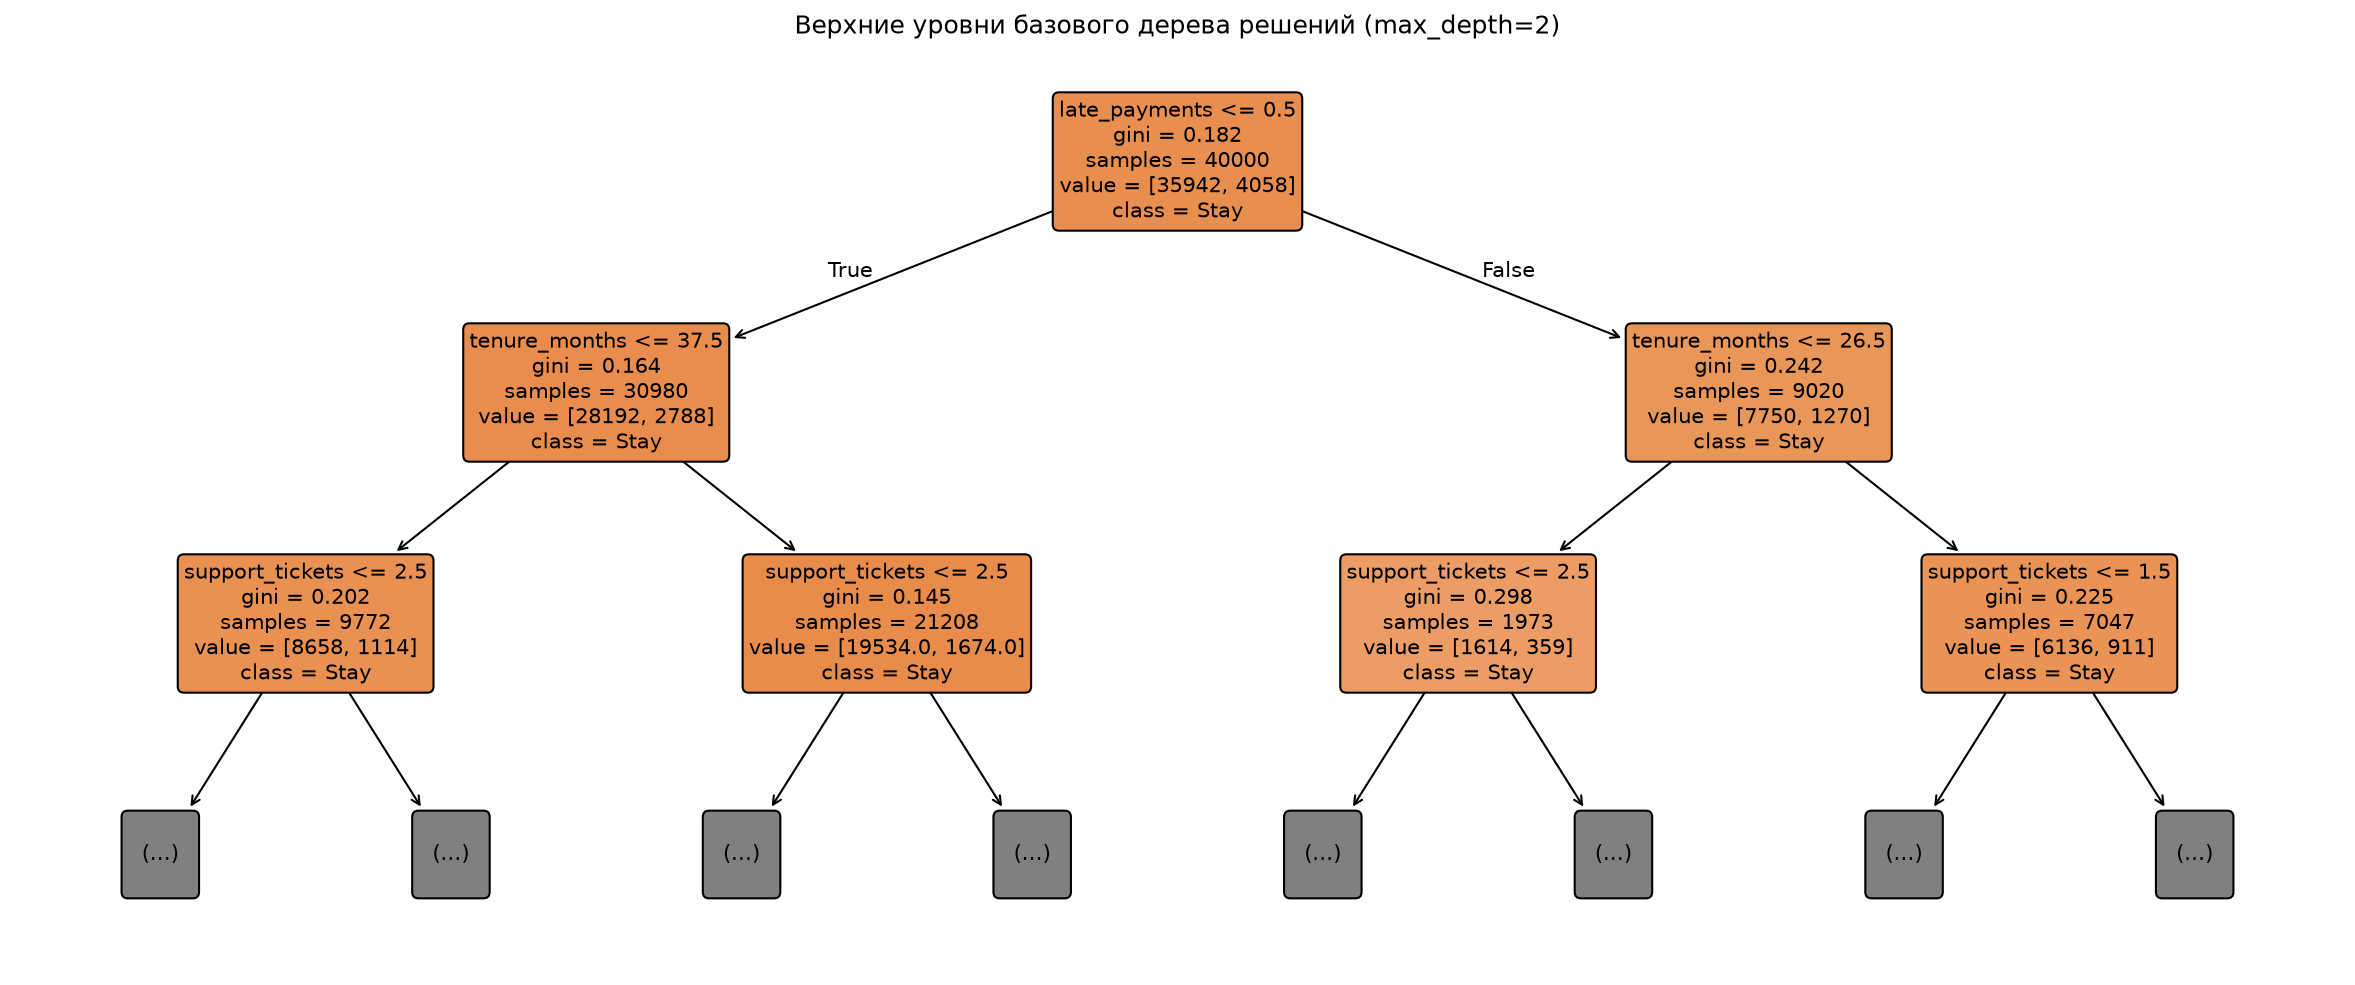

In [4]:
# базовое дерево без искусственных ограничений
tree_base = DecisionTreeClassifier(random_state=42) #  реализует алгоритм CART (Classification and Regression Trees), бинарное дерево решений для классификации
tree_base.fit(X_train_prep, y_train)

print(f"Глубина базового дерева: {tree_base.get_depth()}")
print(f"Количество листьев: {tree_base.get_n_leaves()}")
print(f"Общее количество узлов: {tree_base.tree_.node_count}")

# визуализация верхних уровней дерева (глубина 2 для наглядности)
plt.figure(figsize=(20, 8), dpi=150)
plot_tree(tree_base, max_depth=2, feature_names=feature_names, class_names=['Stay', 'Churn'], filled=True, rounded=True, fontsize=10)
plt.title("Верхние уровни базового дерева решений (max_depth=2)")
plt.show()

#### 1. Сложность базовой модели:
* Фактическая глубина: 42 уровня
* Количество листьев: 4931
* Общее количество узлов: 9861
* **Вывод:** Дерево без ограничений разрослось до огромных размеров, пытаясь идеально разделить обучающую выборку (вплоть до отдельных объектов в листьях). Это явный признак избыточной сложности и переобучения

#### 2. Интерпретация корневого узла (Root Node):
* Используемый признак и порог: late_payments <= 0.5 (поскольку признак целочисленный, это означает разделение: "0 просрочек" против "1 и более просрочек")
* Количество объектов в узле: 40000 (вся обучающая выборка)
* Распределение классов: value = [35942, 4058] (35 942 лояльных клиента, 4 058 ушедших)
* Критерий Джини: gini = 0.182
* Бизнес-смысл: Алгоритм выделил платежную дисциплину как самый информативный фактор оттока на первом шаге. Клиенты без просрочек уходят реже

#### 3. Интерпретация дочерних узлов 1-го уровня:
* **Левая ветка (Условие True: late_payments == 0):**
  * Попадает 30980 клиентов
  * Класс 0: 28192, Класс 1: 2788. Доля оттока здесь составляет всего 9.0% (2788 / 30980)
  * Дальнейшее разбиение происходит по признаку tenure_months <= 37.5 (стаж клиента более/менее ~3 лет)
* **Правая ветка (Условие False: late_payments >= 1):**
  * Попадает 9020 клиентов с просрочками
  * Класс 0: 7750, Класс 1: 1270. Доля оттока возрастает до 14.1% (1270 / 9020), а неоднородность Gini увеличивается до 0.242
  * Дальнейшее правило проверяет порог tenure_months <= 26.5 (для клиентов с просрочками порог "новичка" смещается к ~2 годам)

#### 4. Детальный разбор узла 2-го уровня (Правый-Левый):
* Путь к узлу: late_payments > 0.5 -> tenure_months <= 26.5.
* Кто попадает: Клиенты с наличием просрочек по платежам, которые пользуются услугами компании не более 26.5 месяцев (относительно новые клиенты с финансовыми задержками)
* Параметры узла:
  * samples = 1973
  * value = [1614, 359] (доля оттока составляет 18.2% — максимальная концентрация риска среди рассмотренных узлов верхнего уровня)
  * gini = 0.298
* Правило дальнейшего ветвления: support_tickets <= 2.5
  * Если такой проблемный клиент обращается в техподдержку 3 и более раз, риск оттока возрастает лавинообразно

Посмотрим на первые 5 строк вместе с целевой переменной churn и расчитаем по ним критерий Джинни

In [5]:
df.loc[X_train.head().index, ['late_payments', 'tenure_months', 'churn']]

,late_payments,tenure_months,churn
26921,1,4,1
7764,0,67,0
39890,1,62,0
17560,0,43,0
5812,0,109,0


Ручной расчет см. в тетради

---

### 4. Исследование влияния сложности дерева на качество

**Гипотеза:** Увеличение глубины дерева улучшает качество на обучающей выборке, однако после определенного значения может привести к ухудшению качества на новых данных

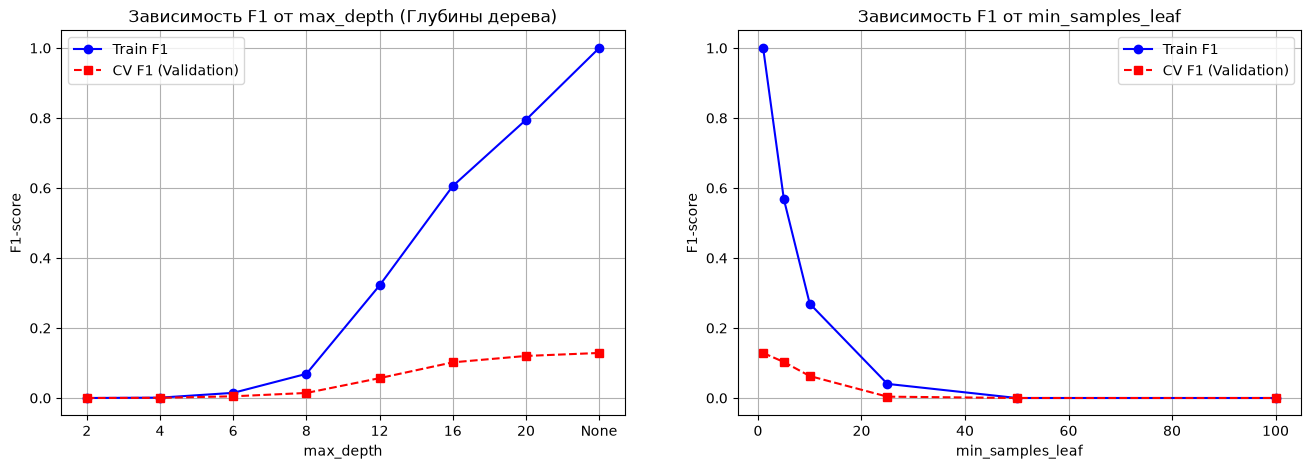

In [6]:
# 1 Исследование max_depth
depths = [2, 4, 6, 8, 12, 16, 20, None]
depth_labels = [str(d) for d in depths]

train_scores_depth = []
cv_scores_depth = []
tree_nodes_depth = []

for d in depths:
    clf = DecisionTreeClassifier(max_depth=d, random_state=42)
    # кросс-валидация на обучающих данных (метрика F1)
    cv_score = cross_val_score(clf, X_train_prep, y_train, cv=5, scoring='f1').mean()
    clf.fit(X_train_prep, y_train)

    train_score = f1_score(y_train, clf.predict(X_train_prep))

    train_scores_depth.append(train_score)
    cv_scores_depth.append(cv_score)
    tree_nodes_depth.append(clf.tree_.node_count)

# 2 исследование min_samples_leaf
leafs = [1, 5, 10, 25, 50, 100]
train_scores_leaf = []
cv_scores_leaf = []

for l in leafs:
    clf = DecisionTreeClassifier(min_samples_leaf=l, random_state=42)
    cv_score = cross_val_score(clf, X_train_prep, y_train, cv=5, scoring='f1').mean()
    clf.fit(X_train_prep, y_train)

    train_score = f1_score(y_train, clf.predict(X_train_prep))
    train_scores_leaf.append(train_score)
    cv_scores_leaf.append(cv_score)

# 3 построение графиков
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# график глубины
axes[0].plot(depth_labels, train_scores_depth, 'o-', label='Train F1', color='blue')
axes[0].plot(depth_labels, cv_scores_depth, 's--', label='CV F1 (Validation)', color='red')
axes[0].set_title('Зависимость F1 от max_depth (Глубины дерева)')
axes[0].set_xlabel('max_depth')
axes[0].set_ylabel('F1-score')
axes[0].grid(True)
axes[0].legend()

# график min_samples_leaf
axes[1].plot(leafs, train_scores_leaf, 'o-', label='Train F1', color='blue')
axes[1].plot(leafs, cv_scores_leaf, 's--', label='CV F1 (Validation)', color='red')
axes[1].set_title('Зависимость F1 от min_samples_leaf')
axes[1].set_xlabel('min_samples_leaf')
axes[1].set_ylabel('F1-score')
axes[1].grid(True)
axes[1].legend()

plt.show()

* Явное переобучение с ростом глубины (левый график)

С ростом глубины можно увидеть экспоненциальный рост F1 метрики, который доходит до 1, т.е. модель идеально выучила обучающую выборку. Однако на кросс-валидации качество растет неохотно и едва доходит до 0.18, что свидетельствует о переобучении

* Недообучение при малых глубинах (левый график)

При малых глубинах можно заметить то, что метрика находится около 0, это возникает из-за сильного дисбаланса классов (оттока 10%). Дерево решений по умолчанию относит лист к тому классу, которого там больше 50% -> при маленьких глубинах дерево физически не успевает классифицировать отток и всё относит к классу 0 -> ни разу не угадывает отток, откуда метрика F1 равна 0

* Регуляризация параметром min_samples_leaf (правый график)

Параметр min_samples_leaf задает минимальное число объектов в листе и работает как "тормоз" переобучения (регуляризатор). При увеличении min_samples_leaf синяя линия (Train F1) стремительно падает с 1.0 до 0: модель лишается возможности создавать мелкие листья под единичные примеры. При min_samples_leaf >= 25 метрика валидации падает в 0, так как алгоритму запрещено выделять подвыборки менее 25 клиентов, а значит, редкий 10%-й класс снова полностью поглощается большинством

**Вывод:** Обычное дерево решений со стандартными параметрами на несбалансированных данных не работает, для корректной работы нужна балансировка, которую применим в пункте 5. Для этого нам понадобится включить параметр class_weight='balanced', который заставит дерево штрафовать ошибки на редком классе и поднимет сбалансированную точность

Гипотеза: "Увеличение сложности дерева улучшает качество на обучении, но после определенного предела ухудшает его на новых данных" - полностью подтвердилась экспериментально. Без ограничений модель демонстрирует стопроцентное переобучение с потерей качества на валидации

In [7]:
# формирование экспериментальной таблицы
results_depth = []

for d, nodes in zip(depths, tree_nodes_depth):
    clf = DecisionTreeClassifier(max_depth=d, random_state=42)
    clf.fit(X_train_prep, y_train)

    # метрики на Train и Test
    train_f1 = f1_score(y_train, clf.predict(X_train_prep))
    test_f1 = f1_score(y_test, clf.predict(X_test_prep))
    test_acc = accuracy_score(y_test, clf.predict(X_test_prep))
    test_bal_acc = balanced_accuracy_score(y_test, clf.predict(X_test_prep))

    cv_idx = depths.index(d)
    cv_f1 = cv_scores_depth[cv_idx]

    results_depth.append({
        'max_depth': str(d),
        'Кол-во узлов': nodes,
        'Train F1': round(train_f1, 4),
        'CV F1': round(cv_f1, 4),
        'Test F1': round(test_f1, 4),
        'Test Balanced Acc': round(test_bal_acc, 4),
        'Test Accuracy': round(test_acc, 4)
    })

df_depth_results = pd.DataFrame(results_depth)
print("Экспериментальная таблица исследования сложности дерева:")
display(df_depth_results)

Экспериментальная таблица исследования сложности дерева:


,max_depth,Кол-во узлов,Train F1,CV F1,Test F1,Test Balanced Acc,Test Accuracy
0,2,7,0.0000,0.0000,0.0000,0.5000,0.8985
1,4,31,0.0010,0.0005,0.0000,0.5000,0.8985
2,6,113,0.0147,0.0048,0.0000,0.4997,0.8979
3,8,337,0.0690,0.0144,0.0150,0.5013,0.8946
4,12,1713,0.3217,0.0567,0.0356,0.4997,0.8807
5,16,4123,0.6056,0.1019,0.0753,0.5016,0.8551
6,20,6393,0.7948,0.1201,0.1133,0.5100,0.8325
7,None,9861,1.0000,0.1287,0.1271,0.5090,0.8008


1. Иллюстрация "Парадокса точности" (Accuracy Paradox):
   * При малой глубине (max_depth = 2) метрика Test Accuracy максимальна (89.85%). Однако это ложное качество: модель ни разу не предсказала уход клиента (Test F1 = 0.0, Balanced Accuracy = 0.5000, что эквивалентно константному угадыванию). 89.85% - это просто доля мажоритарного класса в тесте
2. Динамика переобучения:
   * С ростом глубины количество узлов экспоненциально растет: от 7 узлов (depth=2) до 9861 узла (depth=None)
   * На обучающей выборке Train F1 монотонно возрастает от 0.0 до идеального 1.0000
   * На тесте и валидации метрика F1 сначала растет медленно, достигая максимума всего в ~0.1271 при depth=None, при этом общая Test Accuracy падает с 89.85% до 80.08% из-за ложных срабатываний на переобученных листьях
3. Вывод для следующего шага:
   * Стандартный критерий Джини без учета дисбаланса не способен эффективно выделить меньшинство (отток). Для решения проблемы в Задании 5 критически важно использовать взвешивание классов (class_weight='balanced'), что позволит модели обращать равное внимание на оба класса

---

### 5. Настройка гиперпараметров и проверка устойчивости результатов
#### Подбор гиперпараметров через GridSearchCV

In [8]:
# сетка параметров: ограничиваем глубину и добавляем balanced веса
param_grid = {
    'max_depth': [4, 6, 8, 10],
    'min_samples_split': [20, 50, 100],
    'min_samples_leaf': [10, 25, 50],
    'criterion': ['gini', 'entropy'],
    'class_weight': ['balanced']  # компенсирует дисбаланс
}

grid_search = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train_prep, y_train)

best_tree = grid_search.best_estimator_

print("\nРезультаты GridSearchCV:")
print("Лучшие гиперпараметры:", grid_search.best_params_)
print(f"Лучший F1 на кросс-валидации (CV): {grid_search.best_score_:.4f}\n")

# тестируем оптимизированную модель на отложенном тесте
y_test_pred_best = best_tree.predict(X_test_prep)
test_f1_best = f1_score(y_test, y_test_pred_best)
test_bal_acc_best = balanced_accuracy_score(y_test, y_test_pred_best)

print(f"\nTest F1 оптимизированного дерева: {test_f1_best:.4f}")
print(f"Test Balanced Accuracy: {test_bal_acc_best:.4f}")
print(f"Глубина оптимизированного дерева: {best_tree.get_depth()}")
print(f"Количество узлов: {best_tree.tree_.node_count}\n")

Fitting 5 folds for each of 72 candidates, totalling 360 fits

Результаты GridSearchCV:
Лучшие гиперпараметры: {'class_weight': 'balanced', 'criterion': 'entropy', 'max_depth': 4, 'min_samples_leaf': 25, 'min_samples_split': 20}
Лучший F1 на кросс-валидации (CV): 0.2110


Test F1 оптимизированного дерева: 0.1980
Test Balanced Accuracy: 0.5502
Глубина оптимизированного дерева: 4
Количество узлов: 31



In [9]:
# наилучшая модель (гиперпараметры: {'class_weight': 'balanced', 'criterion': 'entropy', 'max_depth': 4, 'min_samples_leaf': 25, 'min_samples_split': 20})

preprocessor_final = ColumnTransformer(transformers=[
    ('num', SimpleImputer(strategy='median'), num_cols),
    ('cat', Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ]), cat_cols)
])

final_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor_final),
    ('tree', DecisionTreeClassifier(**grid_search.best_params_, random_state=42))
])

final_pipeline.fit(X_train, y_train)

# те же метрики, что у best_tree, для проверки, что ничего не сломалось
from sklearn.metrics import f1_score, balanced_accuracy_score
y_pred_final = final_pipeline.predict(X_test)
print("F1 итогового Pipeline на тесте:", round(f1_score(y_test, y_pred_final), 4))
print("Balanced Acc:", round(balanced_accuracy_score(y_test, y_pred_final), 4))
print("Глубина дерева:", final_pipeline.named_steps['tree'].get_depth())
print("Узлов:", final_pipeline.named_steps['tree'].tree_.node_count)

F1 итогового Pipeline на тесте: 0.198
Balanced Acc: 0.5502
Глубина дерева: 4
Узлов: 31


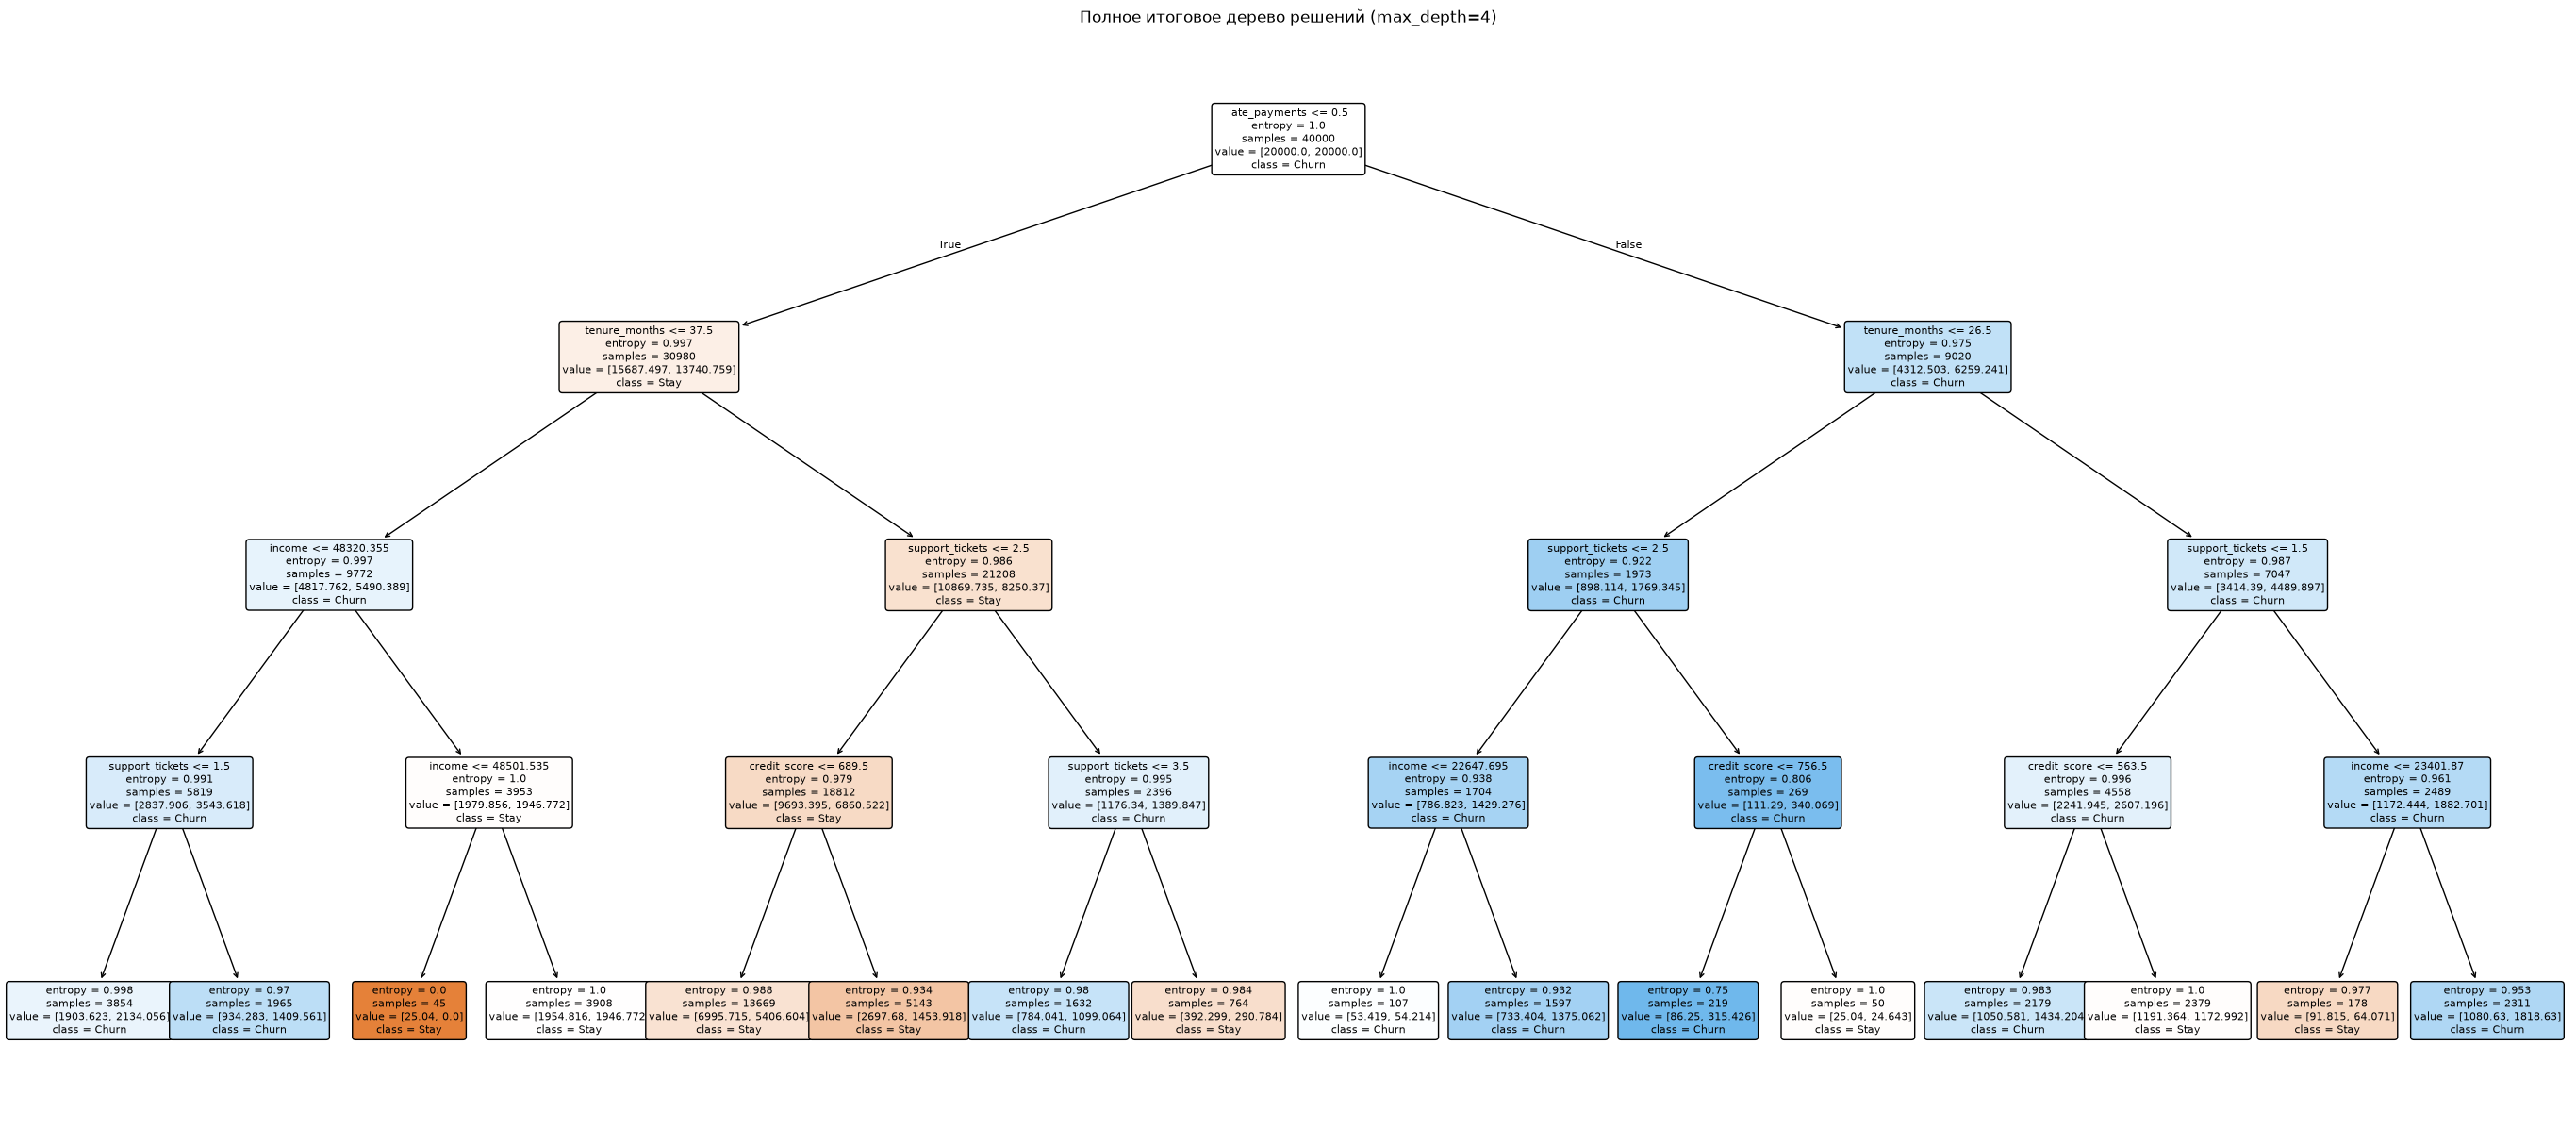

In [10]:
# достаем названия признаков из финального pipeline
feature_names_final = num_cols + list(
    final_pipeline.named_steps['preprocessor']
    .named_transformers_['cat'].named_steps['onehot']
    .get_feature_names_out(cat_cols)
)

plt.figure(figsize=(35, 15))
plot_tree(
    final_pipeline.named_steps['tree'],
    feature_names=feature_names_final,
    class_names=['Stay', 'Churn'],
    filled=True,
    rounded=True,
    fontsize=8
)
plt.title("Полное итоговое дерево решений (max_depth=4)")
plt.show()

In [11]:
# достаём итоговое дерево из пайплайна
tree = final_pipeline.named_steps['tree']

# строим Series: названия признаков -> веса важности
importances = pd.Series(
    tree.feature_importances_,
    index=feature_names_final
)

# сортируем по убыванию и оставляем только ненулевые
importances_sorted = importances[importances > 0].sort_values(ascending=False)

print("Признаки, которые реально используются в дереве:")
display(importances_sorted.to_frame(name='importance').style.background_gradient(cmap='Greens'))

Признаки, которые реально используются в дереве:


,importance
late_payments,0.352729
tenure_months,0.253061
support_tickets,0.212838
credit_score,0.104446
income,0.076926


Важность признака = сумма уменьшений, в нашем случае, энтропии во ВСЕХ узлах, где этот признак использовался

Важность признака это мера того, насколько сильно конкретный признак помог модели разделить классы (чем выше число, тем чаще дерево использовало этот признак для разбиения и тем сильнее эти разбиения улучшали чистоту (уменьшали энтропию или коэффициент Джини))

**Фотографии с решением находятся в директории images/**

#### Проверка устойчивости (5 разных random_state)

In [12]:
seeds = [42, 10, 77, 123, 999]
stability_results = []

for seed in seeds:
    # 1 новое разбиение
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=0.20, random_state=seed, stratify=y
    )

    # 2 предобработка без утечки данных
    X_tr_p = preprocessor.fit_transform(X_tr)
    X_te_p = preprocessor.transform(X_te)

    # 3 модель с лучшими гиперпараметрами
    model = DecisionTreeClassifier(**grid_search.best_params_, random_state=42)
    model.fit(X_tr_p, y_tr)

    # 4 оценка на тесте
    preds = model.predict(X_te_p)
    f1 = f1_score(y_te, preds)
    bal_acc = balanced_accuracy_score(y_te, preds)

    stability_results.append({
        'random_state': seed,
        'Test F1': round(f1, 4),
        'Test Balanced Acc': round(bal_acc, 4),
        'Tree Depth': model.get_depth(),
        'Node Count': model.tree_.node_count
    })

df_stability = pd.DataFrame(stability_results)
print("Результаты проверки устойчивости при различных разбиениях выборки:")
display(df_stability)

print(f"Средний Test F1: {df_stability['Test F1'].mean():.4f} ± {df_stability['Test F1'].std():.4f}")

Результаты проверки устойчивости при различных разбиениях выборки:


,random_state,Test F1,Test Balanced Acc,Tree Depth,Node Count
0,42,0.1980,0.5502,4,31
1,10,0.2067,0.5627,4,29
2,77,0.2030,0.5565,4,31
3,123,0.2053,0.5602,4,31
4,999,0.1976,0.5499,4,31


Средний Test F1: 0.2021 ± 0.0042


1. Сравнение с базовой моделью и экспериментами из Задания 4:
   * В Задании 4 дерево с глубиной 4 без учета весов давало F1 = 0.0000 (предсказывая всем подряд отсутствие оттока)
   * Использование class_weight='balanced' заставило модель штрафовать пропуск меньшинства. В результате метрика Test F1 выросла до 0.1980, а Balanced Accuracy — до 55.02%
   * Оптимальным критерием стал entropy (информационный выигрыш), который в задачах с дисбалансом часто формирует более сбалансированные разбиения, чем `ini
   * Регуляризация параметрами min_samples_leaf=25 и min_samples_split=20 отсекла шум, сократив размер дерева с 9861 до 31 узла
2. Оценка устойчивости:
   * На 5 различных случайных разбиениях (random_state) средний Test F1 = 0.2021 +- 0.0042
   * Минимальный F1: 0.1976, максимальный: 0.2067. Разброс составляет менее 1%
   * Размер дерева стабилен (4 раза ровно 31 узел, 1 раз 29 узлов)
   * **Вывод:** Выбранную конфигурацию дерева можно считать высокоустойчивой к изменению обучающей выборки
3. Примечание о RandomizedSearchCV vs GridSearchCV:
   * В данной работе сетка параметров содержала 72 комбинации (360 обучений при 5-фолдовой кросс-валидации), поэтому полный перебор GridSearchCV занял всего несколько секунд
   * RandomizedSearchCV был бы предпочтительнее при расширении сетки (сотни и тысячи комбинаций) или при настройке непрерывных параметров, так как он находит конфигурации, близкие к оптимуму, за фиксированное контролируемое число итераций

---

### 6. Сравнение с альтернативной моделью

In [13]:
# 1 для линейных моделей необходимо масштабирование (StandardScaler)
num_pipe_lr = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

preprocessor_lr = ColumnTransformer([
    ('num', num_pipe_lr, num_cols),
    ('cat', cat_transformer, cat_cols)
])

# обучаем препроцессор для регрессии на X_train
X_train_lr = preprocessor_lr.fit_transform(X_train)
X_test_lr = preprocessor_lr.transform(X_test)

# 2 обучение логистической регрессии с балансировкой весов
log_reg = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
log_reg.fit(X_train_lr, y_train)

# 3 предсказания
y_pred_tree = best_tree.predict(X_test_prep)
y_pred_lr = log_reg.predict(X_test_lr)

# 4 сводная таблица сравнения метрик
metrics_comparison = pd.DataFrame({
    'Метрика': [
        'Accuracy',
        'Balanced Accuracy',
        'F1-score (Churn=1)',
        'Precision (Churn=1)',
        'Recall (Churn=1)'
    ],
    'Оптимальное Дерево Решений': [
        round(accuracy_score(y_test, y_pred_tree), 4),
        round(balanced_accuracy_score(y_test, y_pred_tree), 4),
        round(f1_score(y_test, y_pred_tree), 4),
        round(classification_report(y_test, y_pred_tree, output_dict=True)['1']['precision'], 4),
        round(classification_report(y_test, y_pred_tree, output_dict=True)['1']['recall'], 4)
    ],
    'Логистическая Регрессия': [
        round(accuracy_score(y_test, y_pred_lr), 4),
        round(balanced_accuracy_score(y_test, y_pred_lr), 4),
        round(f1_score(y_test, y_pred_lr), 4),
        round(classification_report(y_test, y_pred_lr, output_dict=True)['1']['precision'], 4),
        round(classification_report(y_test, y_pred_lr, output_dict=True)['1']['recall'], 4)
    ]
})

print("Сравнение моделей на тестовой выборке:")
display(metrics_comparison)

Сравнение моделей на тестовой выборке:


,Метрика,Оптимальное Дерево Решений,Логистическая Регрессия
0,Accuracy,0.6346,0.5821
1,Balanced Accuracy,0.5502,0.5442
2,F1-score (Churn=1),0.1980,0.1943
3,Precision (Churn=1),0.1274,0.1208
4,Recall (Churn=1),0.4443,0.4966


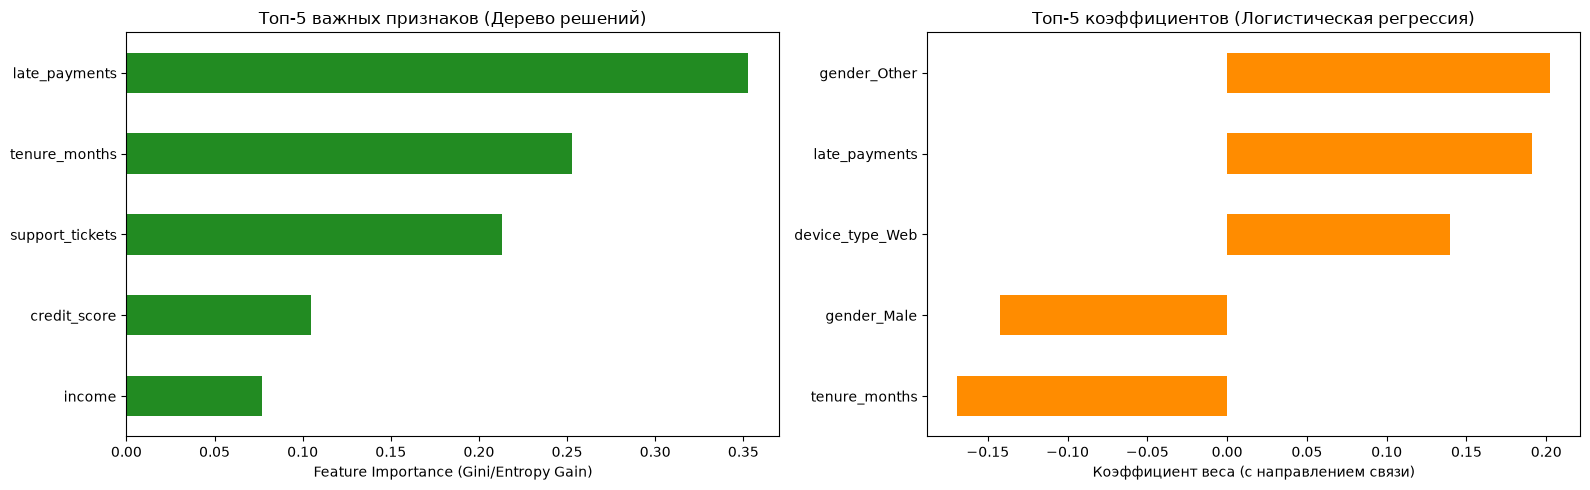

In [14]:
# сравнение важности признаков: Важность в дереве vs Коэффициенты в регрессии
tree_importances = pd.Series(best_tree.feature_importances_, index=feature_names)
top_tree = tree_importances.sort_values(ascending=False).head(5)

lr_coefficients = pd.Series(log_reg.coef_[0], index=feature_names)
top_lr = lr_coefficients.abs().sort_values(ascending=False).head(5)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

top_tree.sort_values().plot(kind='barh', ax=axes[0], color='forestgreen')
axes[0].set_title("Топ-5 важных признаков (Дерево решений)")
axes[0].set_xlabel("Feature Importance (Gini/Entropy Gain)")

lr_coefficients[top_lr.index].sort_values().plot(kind='barh', ax=axes[1], color='darkorange')
axes[1].set_title("Топ-5 коэффициентов (Логистическая регрессия)")
axes[1].set_xlabel("Коэффициент веса (с направлением связи)")

plt.tight_layout()
plt.show()

#### 1. Сопоставление качества (Метрики):
* Обе модели демонстрируют близкое качество: F1-score около 0.198 у дерева против около 0.194 у регрессии, а Balanced Accuracy около 55.0% против около 54.4%
* **Дерево решений** показало более высокую общую точность (Accuracy = 63.46% против 58.21%) и более высокую точность предсказания оттока (Precision = 12.74% против 12.08%)
* **Логистическая регрессия** за счет сдвига порога при class_weight='balanced' показала чуть более высокую полноту (Recall = 49.66% против 44.43%), поймав на 5% больше уходящих клиентов ценой большего числа ложных тревог

#### 2. Особенности интерпретации:
* Дерево решений (глубина 4, 31 узел):
  Формирует понятные человеку логические цепочки правил ("ЕСЛИ просрочек >= 1 И стаж <= 26.5 мес И обращений >= 3 -> риск оттока"). Дерево автоматически учитывает **нелинейные взаимодействия признаков** без необходимости их ручного конструирования
* **Логистическая регрессия:**
  Оценивает вклад каждого признака в логарифм шансов события, т.е.  как изменение признака меняет шансы на то, что событие произойдет. Интерпретация коэффициентов:
  * Положительный вес late_payments (+0.19) подтверждает, что задержки оплат линейно увеличивают вероятность ухода
  * Отрицательный вес tenure_months (-0.17) показывает, что каждый дополнительный месяц лояльности снижает вероятность оттока
  * Однако модель предполагает независимость признаков и не видит эффектов совместного влияния признаков

#### 3. Какая модель предпочтительнее для прикладной задачи?
Для задачи предотвращения оттока клиентов **предпочтительнее Дерево решений**:
1. Оно дает меньше ложных тревог (выше Precision и Accuracy), экономя маркетинговый бюджет на удержание
2. Правила дерева можно напрямую заложить в автоматические триггеры CRM-системы (например, триггерная отправка бонуса при достижении 3-го обращения в саппорт)

---

### 7. Анализ ошибок и формулирование выводов

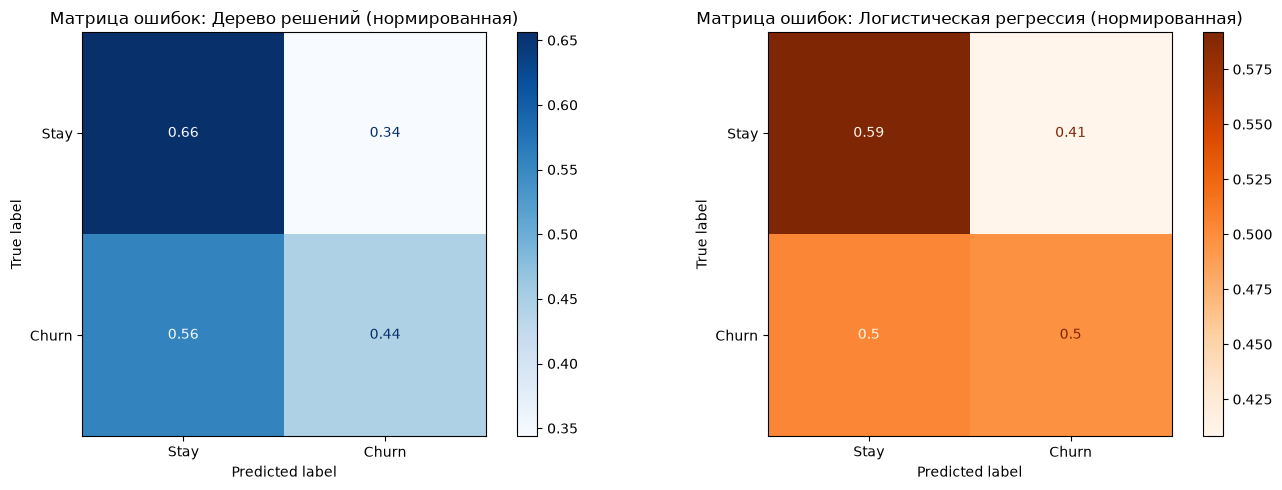

Примеры False Negatives (модель пропустила уход клиента):


,age,tenure_months,late_payments,support_tickets,monthly_charges,y_true,y_pred
42060,48,43,0,2,1619.78,1,0
28124,62,55,0,1,779.16,1,0
26746,29,108,0,0,1255.18,1,0


Примеры False Positives (ложная тревога, клиент остался):


,age,tenure_months,late_payments,support_tickets,monthly_charges,y_true,y_pred
35814,64,32,0,0,618.74,0,1
29203,61,55,1,2,1748.00,0,1
1677,47,31,2,1,1167.84,0,1


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1 нормированные матрицы ошибок
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_tree, ax=axes[0], cmap='Blues',
    display_labels=['Stay', 'Churn'], normalize='true'
)
axes[0].set_title("Матрица ошибок: Дерево решений (нормированная)")

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_lr, ax=axes[1], cmap='Oranges',
    display_labels=['Stay', 'Churn'], normalize='true'
)
axes[1].set_title("Матрица ошибок: Логистическая регрессия (нормированная)")

plt.tight_layout()
plt.show()

# 2 выборка конкретных примеров с ошибками дерева
analysis_df = X_test.copy()
analysis_df['y_true'] = y_test
analysis_df['y_pred'] = y_pred_tree

# ложноотрицательные (FN): клиент ушел (1), но модель решила, что он останется (0)
fn_samples = analysis_df[(analysis_df['y_true'] == 1) & (analysis_df['y_pred'] == 0)].head(3)

# ложноположительные (FP): клиент остался (0), но модель спрогнозировала уход (1)
fp_samples = analysis_df[(analysis_df['y_true'] == 0) & (analysis_df['y_pred'] == 1)].head(3)

print("Примеры False Negatives (модель пропустила уход клиента):")
display(fn_samples[['age', 'tenure_months', 'late_payments', 'support_tickets', 'monthly_charges', 'y_true', 'y_pred']])

print("Примеры False Positives (ложная тревога, клиент остался):")
display(fp_samples[['age', 'tenure_months', 'late_payments', 'support_tickets', 'monthly_charges', 'y_true', 'y_pred']])

#### 1. Анализ матриц ошибок (Confusion Matrix):
* Дерево решений:
  * Успешно определяет 66% лояльных клиентов (True Negative) и 44% клиентов в зоне оттока (Recall / True Positive)
  * Доля ложных тревог (False Positive) составляет 34%, а доля пропущенного оттока (False Negative) — 56%
* Сравнение с логистической регрессией:
  * Регрессия ловит на 6% больше оттока (Recall = 50%), но делает это ценой резкого роста ложных тревог: 41% лояльных клиентов ошибочно помечаются как уходящие (против 34% у дерева)
  * **Вывод:** Дерево решений работает более сбалансированно и аккуратно относится к лояльной аудитории

#### 2. Содержательный разбор конкретных ошибок по признакам клиентов:

* Пропущенный отток (False Negatives — строки 42060, 28124, 26746):
  * у клиента 26746 стаж составляет 108 месяцев (9 лет!), у него 0 просрочек и 0 обращений в саппорт. С точки зрения правил дерева — это идеальный, максимально надежный клиент. Тем не менее, он ушел (y_true = 1)
  * Причина ошибки: так называемый "тихий отток". Клиенты уходят по внешним причинам, не зафиксированным в признаках датасета (переезд в другой регион, смена сферы деятельности, предложение от конкурента с более выгодной ценой). Имеющихся признаков объективно недостаточно для предсказания таких исходов

* Ложная тревога (False Positives — строки 29203, 1677):
  * У клиента 1677 сразу 2 просрочки платежей и стаж всего 31 месяц. У клиента 29203 очень высокий чек (1 748 у.д.е.) и есть просрочка
  * Причина ошибки: Модель сработала по правилу высокого риска (late_payments >= 1). Однако клиент остался в сервисе - возможно, служба поддержки оперативно решила вопрос или для клиента критически важна непрерывность услуги (высокая стоимость переключения)

#### 3. Проверка гипотезы (из Задания 4):
* Формулировка: "Увеличение глубины дерева улучшает качество на обучающей выборке, однако после определенного значения приводит к ухудшению качества на новых данных".
* **ПОЛНОСТЬЮ ПОДТВЕРЖДЕНА**
  * Базовое дерево без ограничений достигло глубины 42 и показало Train F1 = 1.000, но на тесте точность упала до 80.08%, а размер разросся до 9 861 узла (чистое запоминание обучающего шума)
  * Ограничение глубины до 4 уровней и регуляризация листьями снизили сложность модели до 31 узла, устранили переобучение и обеспечили устойчивую обобщающую способность

#### 4. Общие выводы по лабораторной работе:
1. Сложность дерева: Деревья решений крайне чувствительны к переобучению при отсутствии регуляризации. Параметры max_depth и min_samples_leaf являются ключевыми барьерами против избыточного усложнения структуры
2. Борьба с дисбалансом: При сильном перекосе классов (9:1) стандартное дерево скатывается в константный прогноз мажоритарного класса (F1=0). Введение параметра class_weight='balanced' является обязательным шагом
3. Устойчивость: Проверка на 5 различных случайных сплитах доказала высокую стабильность гиперпараметров (F1 = 0.2021 +- 0.0042, структура сохраняется в 31 узел)
4. Сравнение алгоритмов: Дерево решений превосходит линейную модель в интерпретируемости (бизнес получает готовые правила вида "если - тогда") и дает меньше ложноположительных срабатываний

#### 5. Ограничения исследования и направление развития:
* Ограничение: Одно дерево решений делит данные только по прямым линиям вдоль осей, поэтому граница получается "ступенчатой" и грубой
* Предлагаемый эксперимент: Исследовать ансамблевые алгоритмы (Случайный лес / Random Forest или градиентный бустинг CatBoost / LightGBM). Построить 200–300 деревьев, каждому давать случайный набор признаков. Это сделает границу более гладкой, уменьшит ошибку и может повысить F1-score, при этом результат останется устойчивым